# Rank + Expert Sweep Visual Summary

Compact visualization notebook for the two separate significance analyses:

- expert sweep: top 2 expert counts without CoLA, then best concrete configs inside those counts
- rank sweep: top 2 configured ranks, then best concrete configs inside those ranks

Friedman ranks are used for significance-oriented ordering. Mean scores are shown as descriptive context because mean and Friedman ordering can differ.


In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import friedmanchisquare, wilcoxon
from statsmodels.stats.multitest import multipletests

ROOT = Path("/local/joeldag/repos/moe-study")
EXPERT_REPORT = ROOT / "outputs/pipeline_runs/moe_study_expert_sweep_pipeline_report/expert_pipeline_report.xlsx"
RANK_REPORT = ROOT / "outputs/pipeline_runs/moe_study_rank_sweep_pipeline_report/rank_pipeline_report.xlsx"

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180})

SCORE_FAMILIES = ["Belebele", "FLORES en->x", "FLORES x->en", "SIB200", "Taxi1500"]


def holm(pvals):
  return multipletests(pd.Series(pvals, dtype=float), method="holm")[1]


def load_primary_metrics(report):
  raw = pd.read_excel(report, sheet_name="benchmark_raw")
  primary = raw[
    ((raw.benchmark == "Belebele") & (raw.metric == "acc_norm")) |
    ((raw.benchmark == "FLORES") & (raw.metric.astype(str).str.startswith("bits_per_byte "))) |
    ((raw.benchmark == "SIB200") & (raw.metric == "acc")) |
    ((raw.benchmark == "Taxi1500") & (raw.metric == "acc"))
  ].copy()
  primary = primary[~primary["is_baseline"].astype(str).str.lower().isin(["true", "1", "yes"])]

  primary["direction"] = primary.metric.astype(str).str.extract(r"(en->x|x->en)", expand=False).fillna("")
  primary["score_family"] = np.where(primary.benchmark.eq("FLORES"), "FLORES " + primary.direction, primary.benchmark)
  primary["value"] = pd.to_numeric(primary.value, errors="coerce")

  g = primary.groupby(["score_family", "task", "metric"]).value
  lo, hi = g.transform("min"), g.transform("max")
  primary["normalized_score"] = np.where(primary.better.eq("lower"), (hi - primary.value) / (hi - lo), (primary.value - lo) / (hi - lo))
  primary.loc[(hi - lo).eq(0), "normalized_score"] = 1.0
  return primary.dropna(subset=["value", "normalized_score"]).copy()


def parse_component(run_id):
  for pat in [r"_e(\d+)(?:_|$)", r"_heads(\d+)$", r"_nup(\d+)$", r"_b(\d+)$"]:
    m = re.search(pat, str(run_id))
    if m:
      return int(m.group(1))
  return np.nan


def parse_topk(run_id):
  m = re.search(r"_k(\d+)(?:_|$)", str(run_id))
  return int(m.group(1)) if m else np.nan


def parse_configured_rank(run_id):
  run_id = str(run_id)
  total = re.search(r"_tr(\d+)_", run_id)
  experts = re.search(r"_e(\d+)(?:_|$)", run_id)
  if total and experts:
    return int(total.group(1)) / int(experts.group(1))
  rank = re.search(r"_r(\d+)(?:_|$)", run_id)
  if rank:
    return int(rank.group(1))
  return np.nan


def axis_friedman(df, axis_col, label, levels=None):
  pivot = (
    df.groupby(["score_family", "task", "language", "metric", axis_col])["normalized_score"]
    .mean()
    .unstack(axis_col)
  )
  if levels is not None:
    pivot = pivot.reindex(columns=levels)
  pivot = pivot.dropna()
  cols = list(pivot.columns)
  stat, p = friedmanchisquare(*[pivot[c] for c in cols])
  avg_ranks = pivot.rank(axis=1, ascending=False).mean().sort_values()
  out = pd.DataFrame([{
    "analysis": label,
    "top3": avg_ranks.index[:3].tolist(),
    "n_pairs": len(pivot),
    "friedman_p_raw": p,
    "p_holm": holm([p])[0],
    "significant": holm([p])[0] < 0.05,
    "kendalls_w": stat / (len(pivot) * (pivot.shape[1] - 1)),
    **{f"avg_rank_{c}": avg_ranks.get(c, np.nan) for c in cols},
  }])
  return pivot, avg_ranks, out


def concrete_analysis(df, axis_col, axis_value):
  selected = df[df[axis_col].eq(axis_value)].copy()
  summary = (
    selected.groupby([axis_col, "run_id", "kind"], dropna=False)
    .agg(mean_score=("normalized_score", "mean"), n_rows=("normalized_score", "count"))
    .sort_values("mean_score", ascending=False)
    .reset_index()
  )
  pivot = (
    selected.groupby(["score_family", "task", "language", "metric", "run_id"])["normalized_score"]
    .mean()
    .unstack("run_id")
    .dropna()
  )
  cols = list(pivot.columns)
  stat, p = friedmanchisquare(*[pivot[c] for c in cols])
  avg_ranks = pivot.rank(axis=1, ascending=False).mean().sort_values()
  ordered = avg_ranks.index.tolist()
  friedman = pd.DataFrame([{
    axis_col: axis_value,
    "top3_friedman": ordered[:3],
    "n_pairs": len(pivot),
    "friedman_p_raw": p,
    "p_holm": holm([p])[0],
    "significant": holm([p])[0] < 0.05,
    "kendalls_w": stat / (len(pivot) * (pivot.shape[1] - 1)),
  }])
  rows = []
  for a, b in zip(ordered[:3], ordered[1:4]):
    w = wilcoxon(pivot[a], pivot[b], zero_method="pratt", alternative="greater")
    rows.append({"a": a, "b": b, "mean_a": pivot[a].mean(), "mean_b": pivot[b].mean(), "p_raw": w.pvalue})
  pairwise = pd.DataFrame(rows)
  if len(pairwise):
    pairwise["p_holm"] = holm(pairwise.p_raw)
    pairwise["significant"] = pairwise.p_holm < 0.05
  rank_table = pd.DataFrame({"run_id": ordered, "friedman_avg_rank": [avg_ranks[r] for r in ordered]})
  comparison = summary.merge(rank_table, on="run_id", how="left").sort_values("friedman_avg_rank")
  return summary, comparison, friedman, pairwise


def heatmap(frame, index, columns, values, title, xlabel="", figsize=(8, 4.5), cmap="viridis"):
  table = frame.pivot_table(index=index, columns=columns, values=values, aggfunc="mean")
  fig, ax = plt.subplots(figsize=figsize)
  im = ax.imshow(table, aspect="auto", cmap=cmap, vmin=0, vmax=1)
  ax.set_xticks(range(len(table.columns)), [str(c) for c in table.columns])
  ax.set_yticks(range(len(table.index)), table.index)
  ax.set(title=title, xlabel=xlabel)
  for y, row in enumerate(table.index):
    for x, col in enumerate(table.columns):
      val = table.loc[row, col]
      if pd.notna(val):
        ax.text(x, y, f"{val:.2f}", ha="center", va="center", fontsize=7, color="white" if val < 0.55 else "black")
  fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
  plt.show()
  return table

expert_metrics = load_primary_metrics(EXPERT_REPORT)
expert_metrics["component_count"] = expert_metrics.run_id.map(parse_component)
expert_metrics["top_k"] = expert_metrics.run_id.map(parse_topk)
expert_metrics = expert_metrics.dropna(subset=["component_count"]).copy()
expert_metrics["component_count"] = expert_metrics.component_count.astype(int)

rank_metrics = load_primary_metrics(RANK_REPORT)
rank_metrics["configured_rank"] = rank_metrics.run_id.map(parse_configured_rank)
rank_metrics = rank_metrics.dropna(subset=["configured_rank"]).copy()
rank_metrics["configured_rank"] = rank_metrics.configured_rank.astype(int)

print("expert rows/runs:", len(expert_metrics), expert_metrics.run_id.nunique())
print("rank rows/runs:", len(rank_metrics), rank_metrics.run_id.nunique())


expert rows/runs: 2856 68
rank rows/runs: 2268 54


## Expert Sweep

We use the no-CoLA result for the main expert-count decision because CoLA collapses at larger expert counts and skews the count-level result downward.


,analysis,top3,n_pairs,friedman_p_raw,p_holm,significant,kendalls_w,avg_rank_2,avg_rank_4,avg_rank_8,avg_rank_16,avg_rank_32
0,with_cola,"[2, 4, 8]",42,3.073507e-18,3.073507e-18,True,0.525397,1.738095,2.047619,3.071429,4.547619,3.595238
1,no_cola,"[32, 2, 4]",42,8.742769e-15,8.742769e-15,True,0.428345,2.547619,2.738095,4.142857,3.928571,1.642857


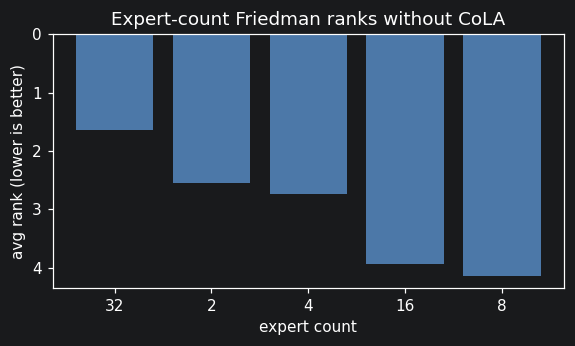

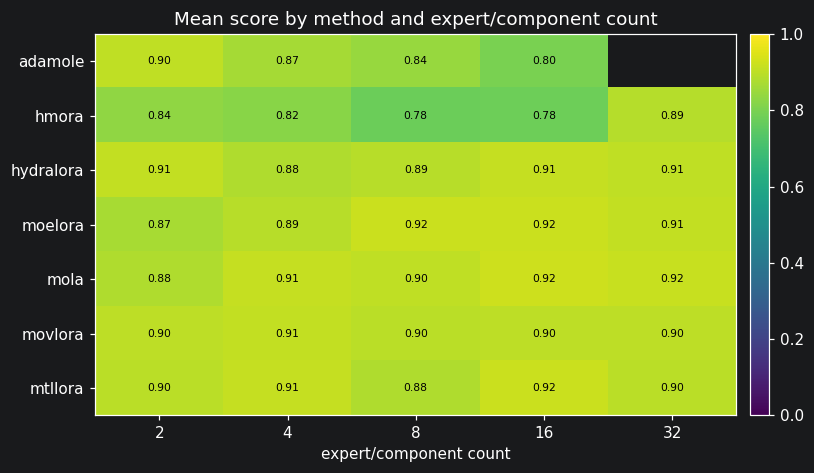

Top 2 expert counts without CoLA: [32, 2]


In [2]:
counts = [2, 4, 8, 16, 32]
expert_all_pivot, expert_all_ranks, expert_all_test = axis_friedman(expert_metrics, "component_count", "with_cola", counts)
expert_no_cola = expert_metrics[expert_metrics.kind.ne("cola")].copy()
expert_pivot, expert_ranks, expert_test = axis_friedman(expert_no_cola, "component_count", "no_cola", counts)

display(pd.concat([expert_all_test, expert_test], ignore_index=True))

rank_plot = pd.DataFrame({"expert_count": expert_ranks.index.astype(int), "friedman_avg_rank": expert_ranks.values})
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(rank_plot.expert_count.astype(str), rank_plot.friedman_avg_rank, color="#4C78A8")
ax.invert_yaxis()
ax.set(title="Expert-count Friedman ranks without CoLA", xlabel="expert count", ylabel="avg rank (lower is better)")
plt.show()

expert_scores = (
  expert_no_cola.groupby(["run_id", "kind", "component_count"], dropna=False)["normalized_score"]
  .mean().reset_index(name="mean_score")
)
heatmap(expert_scores, "kind", "component_count", "mean_score", "Mean score by method and expert/component count", "expert/component count")

top_expert_counts = expert_test.top3.iloc[0][:2]
print("Top 2 expert counts without CoLA:", top_expert_counts)


Expert count 32: mean-score order vs Friedman order


,component_count,run_id,kind,mean_score,friedman_avg_rank
0,32,moelora_r2_e32_k8,moelora,0.935823,4.964286
2,32,adamoe_1_r2_e32_k4,mola,0.925381,5.440476
4,32,moelora_r2_e32_k4,moelora,0.916821,5.559524
1,32,adamoe_1_r2_e32_k2,mola,0.930762,6.000000
8,32,hydralora_r2_heads32,hydralora,0.906068,6.309524
6,32,adamoe_1_r2_e32_k8,mola,0.907511,6.345238
3,32,adamoe_1_r2_e32_k16,mola,0.917686,7.750000
11,32,adamoe_1_r2_e32_k1,mola,0.898315,8.476190


,component_count,top3_friedman,n_pairs,friedman_p_raw,p_holm,significant,kendalls_w
0,32,"[moelora_r2_e32_k8, adamoe_1_r2_e32_k4, moelor...",42,2.879303e-47,2.879303e-47,True,0.395597


,a,b,mean_a,mean_b,p_raw,p_holm,significant
0,moelora_r2_e32_k8,adamoe_1_r2_e32_k4,0.935823,0.925381,0.063570,0.190710,False
1,adamoe_1_r2_e32_k4,moelora_r2_e32_k4,0.925381,0.916821,0.150997,0.301994,False
2,moelora_r2_e32_k4,adamoe_1_r2_e32_k2,0.916821,0.930762,0.601177,0.601177,False


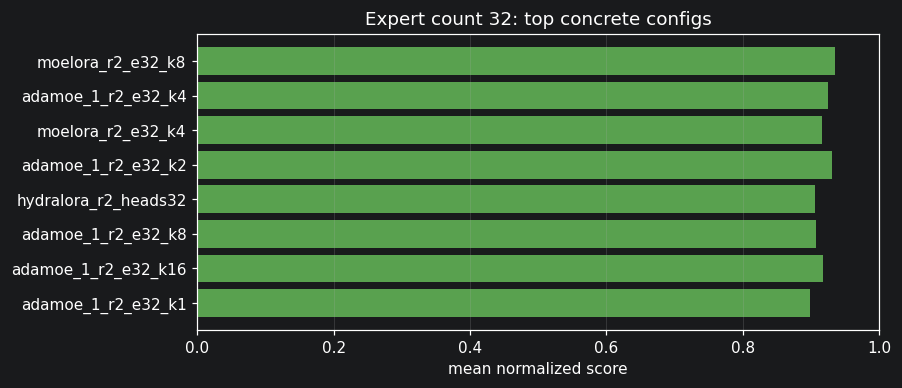

Expert count 2: mean-score order vs Friedman order


,component_count,run_id,kind,mean_score,friedman_avg_rank
0,2,hydralora_r2_heads2,hydralora,0.906931,2.380952
2,2,mov_dense_e2,movlora,0.900182,3.238095
4,2,adamoe_1_r2_e2_k1,mola,0.881197,3.297619
3,2,mtllora_r2_nup2,mtllora,0.897705,3.547619
1,2,adamole_r2_e2,adamole,0.903847,4.202381
5,2,moelora_r2_e2_k1,moelora,0.867839,5.107143
6,2,hmora_r2_e2_k1,hmora,0.835893,6.226190


,component_count,top3_friedman,n_pairs,friedman_p_raw,p_holm,significant,kendalls_w
0,2,"[hydralora_r2_heads2, mov_dense_e2, adamoe_1_r...",42,1.301991e-17,1.301991e-17,True,0.364148


,a,b,mean_a,mean_b,p_raw,p_holm,significant
0,hydralora_r2_heads2,mov_dense_e2,0.906931,0.900182,0.500000,1.000000,False
1,mov_dense_e2,adamoe_1_r2_e2_k1,0.900182,0.881197,0.045703,0.137109,False
2,adamoe_1_r2_e2_k1,mtllora_r2_nup2,0.881197,0.897705,0.640169,1.000000,False


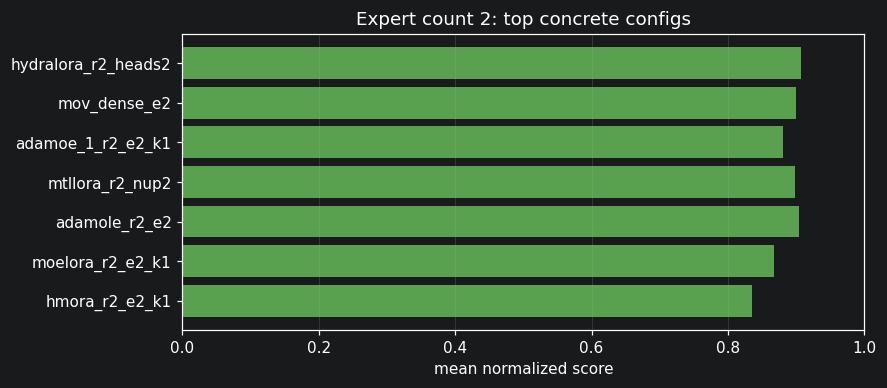

In [3]:
expert_concrete_outputs = {}
for count in top_expert_counts:
  summary, comparison, friedman, pairwise = concrete_analysis(expert_no_cola, "component_count", count)
  expert_concrete_outputs[count] = (summary, comparison, friedman, pairwise)

  print(f"Expert count {count}: mean-score order vs Friedman order")
  display(comparison[["component_count", "run_id", "kind", "mean_score", "friedman_avg_rank"]].head(8))
  display(friedman)
  display(pairwise)

  top = comparison.head(8).iloc[::-1]
  fig, ax = plt.subplots(figsize=(8, 3.5))
  ax.barh(top.run_id, top.mean_score, color="#59A14F")
  ax.set(title=f"Expert count {count}: top concrete configs", xlabel="mean normalized score", xlim=(0, 1))
  ax.grid(axis="x", alpha=0.25)
  plt.show()


## Rank Sweep

Rank analysis uses **configured rank** as the native method rank knob. For MoE rank runs, configured rank is `encoded_total_rank / num_experts`.


,analysis,top3,n_pairs,friedman_p_raw,p_holm,significant,kendalls_w,avg_rank_2,avg_rank_4,avg_rank_8,avg_rank_16,avg_rank_32,avg_rank_64,avg_rank_128,avg_rank_256,avg_rank_512,avg_rank_1024
0,configured_rank,"[2, 4, 1024]",42,1.545907e-60,1.545907e-60,True,0.808957,1.321429,2.25,4.357143,5.404762,6.857143,7.261905,8.738095,9.928571,4.666667,4.214286


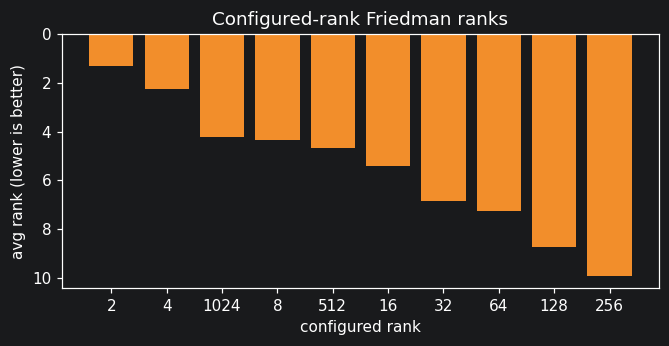

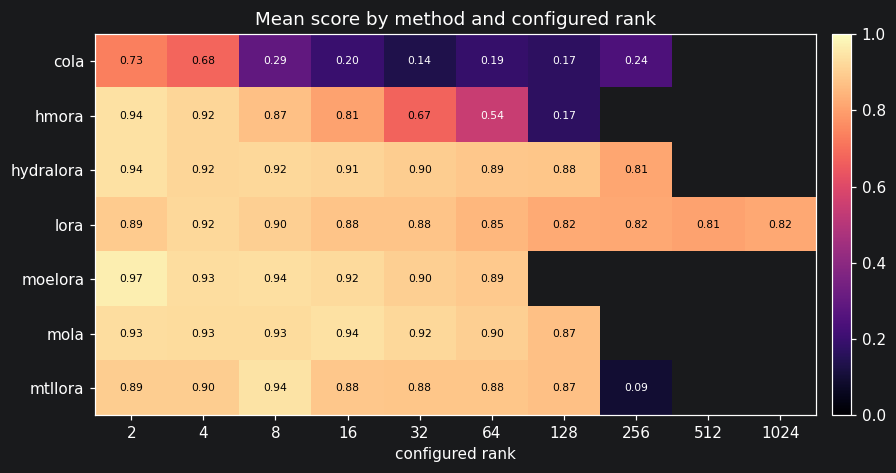

Top 2 configured ranks: [2, 4]


In [4]:
rank_pivot, rank_avg, rank_test = axis_friedman(rank_metrics, "configured_rank", "configured_rank")
display(rank_test)

rank_plot = pd.DataFrame({"configured_rank": rank_avg.index.astype(int), "friedman_avg_rank": rank_avg.values})
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(rank_plot.configured_rank.astype(str), rank_plot.friedman_avg_rank, color="#F28E2B")
ax.invert_yaxis()
ax.set(title="Configured-rank Friedman ranks", xlabel="configured rank", ylabel="avg rank (lower is better)")
plt.show()

rank_scores = (
  rank_metrics.groupby(["run_id", "kind", "configured_rank"], dropna=False)["normalized_score"]
  .mean().reset_index(name="mean_score")
)
heatmap(rank_scores, "kind", "configured_rank", "mean_score", "Mean score by method and configured rank", "configured rank", figsize=(9, 4.5), cmap="magma")

top_ranks = rank_test.top3.iloc[0][:2]
print("Top 2 configured ranks:", top_ranks)


Configured rank 2: mean-score order vs Friedman order


,configured_rank,run_id,kind,mean_score,friedman_avg_rank
0,2,moelora_tr16_e8_k2,moelora,0.967458,2.571429
3,2,mola_tr16_e8_k6,mola,0.932036,2.726190
2,2,hydralora_r2,hydralora,0.939398,3.226190
4,2,mtllora_r2,mtllora,0.894854,4.047619
5,2,lora_r2,lora,0.892762,4.285714
1,2,hmora_tr16_e8_k2,hmora,0.940570,4.333333
6,2,cola_r2,cola,0.731217,6.809524


,configured_rank,top3_friedman,n_pairs,friedman_p_raw,p_holm,significant,kendalls_w
0,2,"[moelora_tr16_e8_k2, mola_tr16_e8_k6, hydralor...",42,7.901701e-22,7.901701e-22,True,0.444305


,a,b,mean_a,mean_b,p_raw,p_holm,significant
0,moelora_tr16_e8_k2,mola_tr16_e8_k6,0.967458,0.932036,0.006880,0.013760,True
1,mola_tr16_e8_k6,hydralora_r2,0.932036,0.939398,0.514802,0.514802,False
2,hydralora_r2,mtllora_r2,0.939398,0.894854,0.000886,0.002658,True


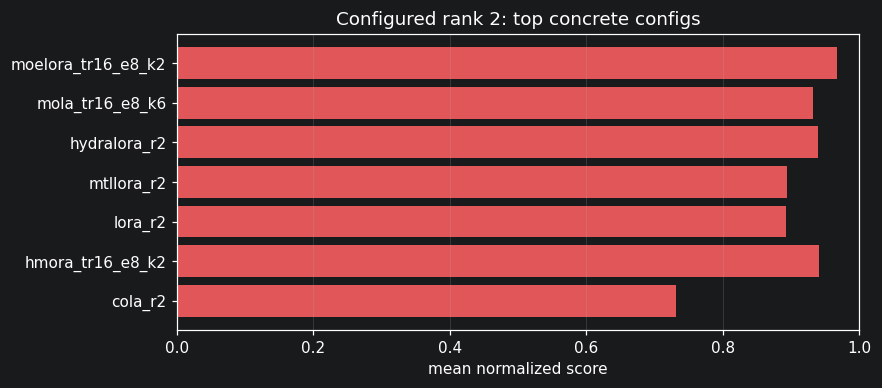

Configured rank 4: mean-score order vs Friedman order


,configured_rank,run_id,kind,mean_score,friedman_avg_rank
1,4,mola_tr32_e8_k6,mola,0.927662,2.607143
0,4,moelora_tr32_e8_k2,moelora,0.931373,2.928571
2,4,lora_r4,lora,0.918843,3.130952
3,4,hydralora_r4,hydralora,0.915862,3.369048
5,4,mtllora_r4,mtllora,0.896977,4.261905
4,4,hmora_tr32_e8_k2,hmora,0.915299,4.702381
6,4,cola_r4,cola,0.678701,7.000000


,configured_rank,top3_friedman,n_pairs,friedman_p_raw,p_holm,significant,kendalls_w
0,4,"[mola_tr32_e8_k6, moelora_tr32_e8_k2, lora_r4]",42,1.132114e-24,1.132114e-24,True,0.498057


,a,b,mean_a,mean_b,p_raw,p_holm,significant
0,mola_tr32_e8_k6,moelora_tr32_e8_k2,0.927662,0.931373,0.687102,0.687102,False
1,moelora_tr32_e8_k2,lora_r4,0.931373,0.918843,0.132887,0.265774,False
2,lora_r4,hydralora_r4,0.918843,0.915862,0.050696,0.152089,False


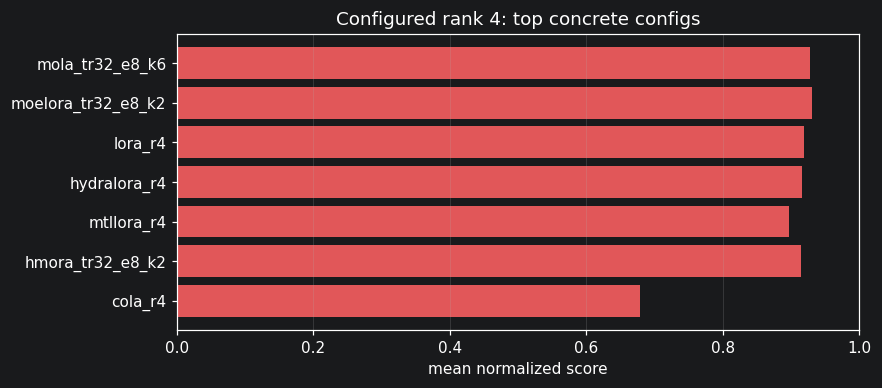

In [5]:
rank_concrete_outputs = {}
for rank in top_ranks:
  summary, comparison, friedman, pairwise = concrete_analysis(rank_metrics, "configured_rank", rank)
  rank_concrete_outputs[rank] = (summary, comparison, friedman, pairwise)

  print(f"Configured rank {rank}: mean-score order vs Friedman order")
  display(comparison[["configured_rank", "run_id", "kind", "mean_score", "friedman_avg_rank"]].head(8))
  display(friedman)
  display(pairwise)

  top = comparison.head(8).iloc[::-1]
  fig, ax = plt.subplots(figsize=(8, 3.5))
  ax.barh(top.run_id, top.mean_score, color="#E15759")
  ax.set(title=f"Configured rank {rank}: top concrete configs", xlabel="mean normalized score", xlim=(0, 1))
  ax.grid(axis="x", alpha=0.25)
  plt.show()


## Compact Findings

The tables above intentionally show both mean score and Friedman average rank. Mean score describes average performance; Friedman rank is the significance-oriented ordering because it compares paired benchmark/task/language rows and is less sensitive to outliers.


In [6]:
findings = []
findings.append({"question": "Top 2 expert counts", "answer": ", ".join(map(str, top_expert_counts))})
for count, (_, comparison, _, _) in expert_concrete_outputs.items():
  findings.append({"question": f"Top 3 configs for expert count {count}", "answer": "; ".join(comparison.run_id.head(3))})
findings.append({"question": "Top 2 configured ranks", "answer": ", ".join(map(str, top_ranks))})
for rank, (_, comparison, _, _) in rank_concrete_outputs.items():
  findings.append({"question": f"Top 3 configs for rank {rank}", "answer": "; ".join(comparison.run_id.head(3))})

display(pd.DataFrame(findings))


,question,answer
0,Top 2 expert counts,"32, 2"
1,Top 3 configs for expert count 32,moelora_r2_e32_k8; adamoe_1_r2_e32_k4; moelora...
2,Top 3 configs for expert count 2,hydralora_r2_heads2; mov_dense_e2; adamoe_1_r2...
3,Top 2 configured ranks,"2, 4"
4,Top 3 configs for rank 2,moelora_tr16_e8_k2; mola_tr16_e8_k6; hydralora_r2
5,Top 3 configs for rank 4,mola_tr32_e8_k6; moelora_tr32_e8_k2; lora_r4


## Per-Benchmark Trend Lines

These plots show how each approach changes as expert count or configured rank grows. We show three views:

- exact metric values: original metric scale; for FLORES lower is better
- normalized averages: all metrics on a 0-1 scale where higher is better
- Friedman-style average ranks: paired rank consistency across task/language rows; lower is better


In [7]:
def exact_value_frame(frame):
  out = frame.copy()
  # Keep FLORES in the original bits-per-byte scale; lower is better there.
  # Classification benchmarks stay in their original accuracy scale.
  out["exact_score"] = out["value"]
  return out


def plot_benchmark_lines(frame, axis_col, value_col, title, ylabel, *, include_kinds=None, include_families=None, drop_kinds_for_families=None, log_x=True, lower_is_better_flores=False, max_cols=3):
  data = frame.copy()
  if include_kinds is not None:
    data = data[data.kind.isin(include_kinds)].copy()
  if include_families is not None:
    data = data[data.score_family.isin(include_families)].copy()
  if drop_kinds_for_families is not None:
    for family, kinds in drop_kinds_for_families.items():
      data = data[~(data.score_family.eq(family) & data.kind.isin(kinds))].copy()

  grouped = (
    data.groupby(["score_family", "kind", axis_col], dropna=False)[value_col]
    .mean()
    .reset_index()
    .dropna(subset=[axis_col, value_col])
  )
  grouped[axis_col] = grouped[axis_col].astype(int)

  families = [family for family in SCORE_FAMILIES if family in set(grouped.score_family)]
  n_cols = min(max_cols, len(families))
  n_rows = int(np.ceil(len(families) / n_cols))
  fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.0 * n_cols, 3.4 * n_rows), sharex=False, sharey=False)
  axes = np.array(axes).reshape(-1)

  for ax, family in zip(axes, families):
    sub = grouped[grouped.score_family.eq(family)]
    for kind, g in sub.groupby("kind"):
      g = g.sort_values(axis_col)
      ax.plot(g[axis_col], g[value_col], marker="o", linewidth=1.3, markersize=3.5, label=kind)
    if log_x:
      ax.set_xscale("log", base=2)
    ticks = sorted(sub[axis_col].dropna().unique())
    ax.set_xticks(ticks)
    ax.set_xticklabels([str(t) for t in ticks], rotation=45)
    ax.set_title(family)
    ax.set_xlabel(axis_col)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    if value_col == "normalized_score":
      ax.set_ylim(0, 1.02)
    if lower_is_better_flores and family.startswith("FLORES"):
      ax.text(0.02, 0.03, "lower is better", transform=ax.transAxes, fontsize=8)

  for ax in axes[len(families):]:
    ax.axis("off")

  handles, labels = [], []
  for ax in axes[:len(families)]:
    h, l = ax.get_legend_handles_labels()
    for handle, label in zip(h, l):
      if label not in labels:
        handles.append(handle)
        labels.append(label)
  fig.legend(handles, labels, loc="lower center", ncol=min(7, max(1, len(labels))), fontsize=8)
  fig.suptitle(title)
  fig.tight_layout(rect=(0, 0.16, 1, 0.92))
  plt.show()
  return grouped


def friedman_rank_trends(frame, axis_col, unit_cols):
  # For each approach and benchmark family, rank axis values inside paired task/language rows.
  # Lower average rank is better.
  rows = []
  data = frame.dropna(subset=[axis_col]).copy()
  data[axis_col] = data[axis_col].astype(int)

  for (score_family, kind), g in data.groupby(["score_family", "kind"]):
    pivot = (
      g.groupby(unit_cols + [axis_col])["normalized_score"]
      .mean()
      .unstack(axis_col)
      .dropna()
    )
    if pivot.shape[0] < 2 or pivot.shape[1] < 2:
      continue
    avg_ranks = pivot.rank(axis=1, ascending=False).mean().sort_index()
    for level, avg_rank in avg_ranks.items():
      rows.append({
        "score_family": score_family,
        "kind": kind,
        axis_col: int(level),
        "friedman_avg_rank": float(avg_rank),
        "n_pairs": int(len(pivot)),
        "n_levels": int(pivot.shape[1]),
      })
  return pd.DataFrame(rows)


def plot_friedman_rank_lines(rank_frame, axis_col, title, *, include_families=None, drop_kinds_for_families=None, max_cols=3):
  data = rank_frame.copy()
  if include_families is not None:
    data = data[data.score_family.isin(include_families)].copy()
  if drop_kinds_for_families is not None:
    for family, kinds in drop_kinds_for_families.items():
      data = data[~(data.score_family.eq(family) & data.kind.isin(kinds))].copy()
  families = [family for family in SCORE_FAMILIES if family in set(data.score_family)]
  n_cols = min(max_cols, len(families))
  n_rows = int(np.ceil(len(families) / n_cols))
  fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.0 * n_cols, 3.4 * n_rows), sharex=False, sharey=False)
  axes = np.array(axes).reshape(-1)

  for ax, family in zip(axes, families):
    sub = data[data.score_family.eq(family)]
    for kind, g in sub.groupby("kind"):
      g = g.sort_values(axis_col)
      ax.plot(g[axis_col], g["friedman_avg_rank"], marker="o", linewidth=1.3, markersize=3.5, label=kind)
    ticks = sorted(sub[axis_col].dropna().unique())
    ax.set_xscale("log", base=2)
    ax.set_xticks(ticks)
    ax.set_xticklabels([str(t) for t in ticks], rotation=45)
    ax.invert_yaxis()
    ax.set_title(family)
    ax.set_xlabel(axis_col)
    ax.set_ylabel("avg rank (lower is better)")
    ax.grid(alpha=0.25)

  for ax in axes[len(families):]:
    ax.axis("off")

  handles, labels = [], []
  for ax in axes[:len(families)]:
    h, l = ax.get_legend_handles_labels()
    for handle, label in zip(h, l):
      if label not in labels:
        handles.append(handle)
        labels.append(label)
  fig.legend(handles, labels, loc="lower center", ncol=min(7, max(1, len(labels))), fontsize=8)
  fig.suptitle(title)
  fig.tight_layout(rect=(0, 0.16, 1, 0.92))
  plt.show()
  return data


### Expert Count Trends

For FLORES, the main trend plots hide CoLA because its collapse makes the other approaches unreadable. We show CoLA on FLORES separately below. Friedman-rank trend lines are descriptive and separate from the final no-CoLA decision table above.


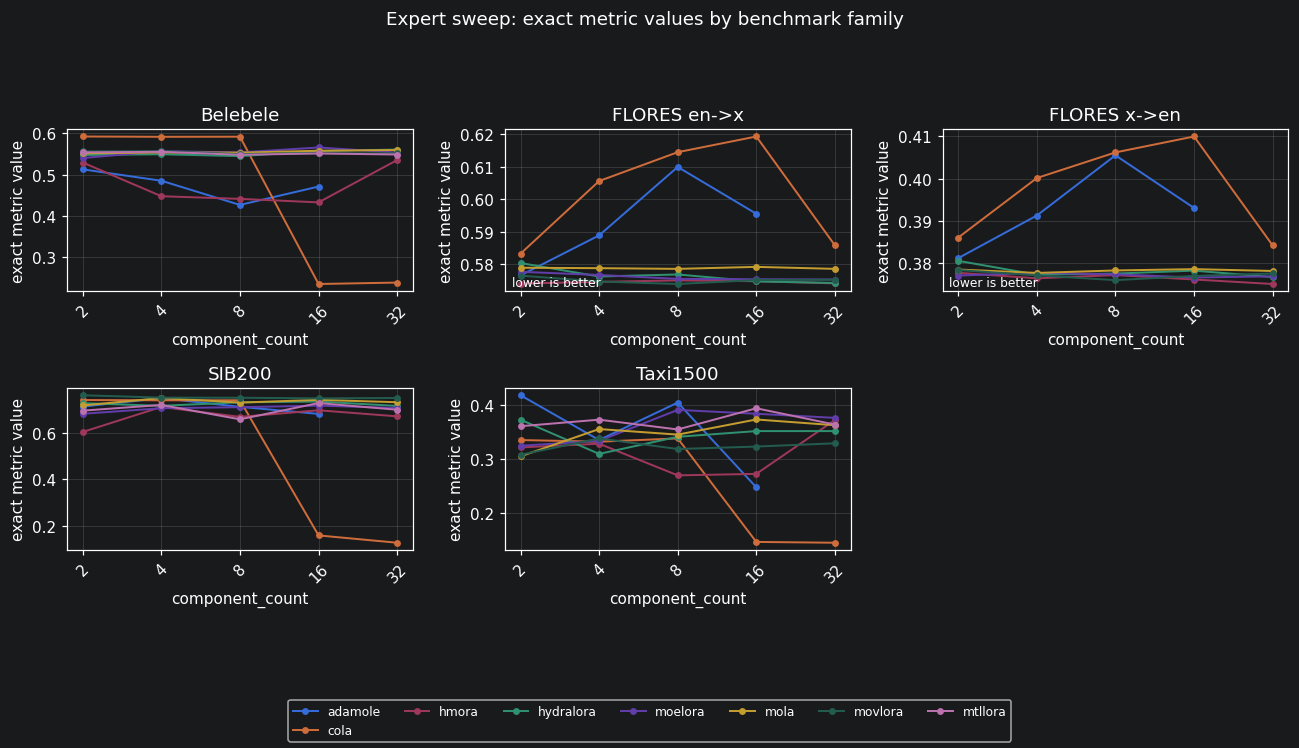

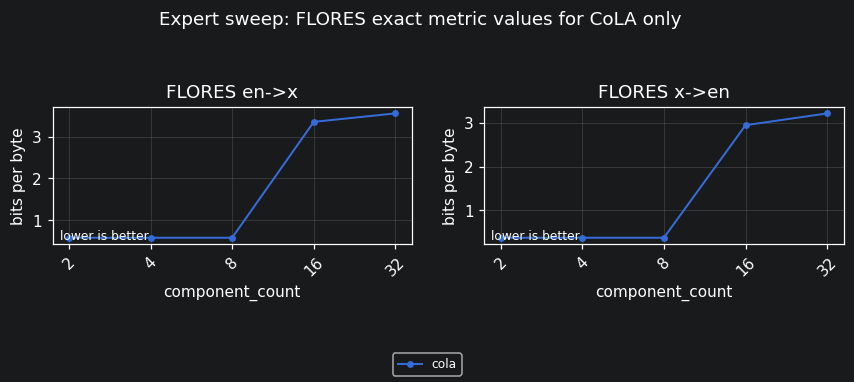

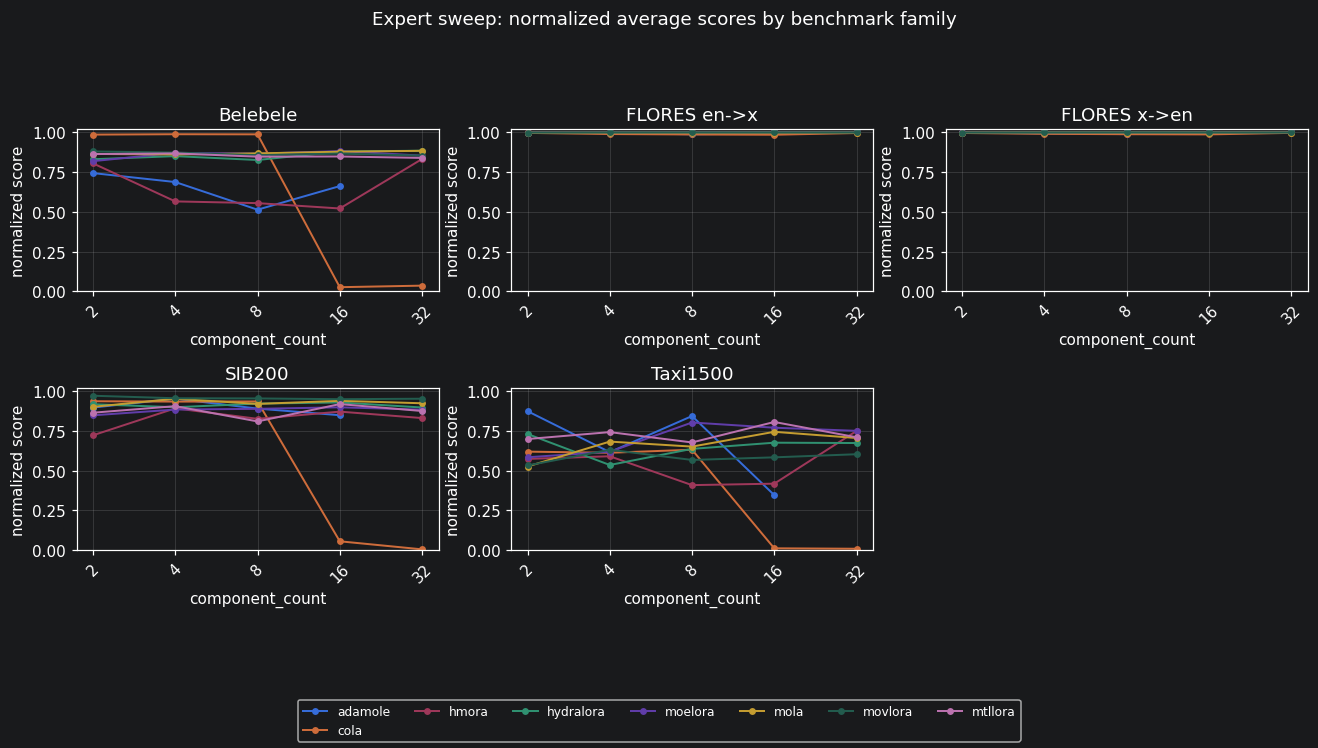

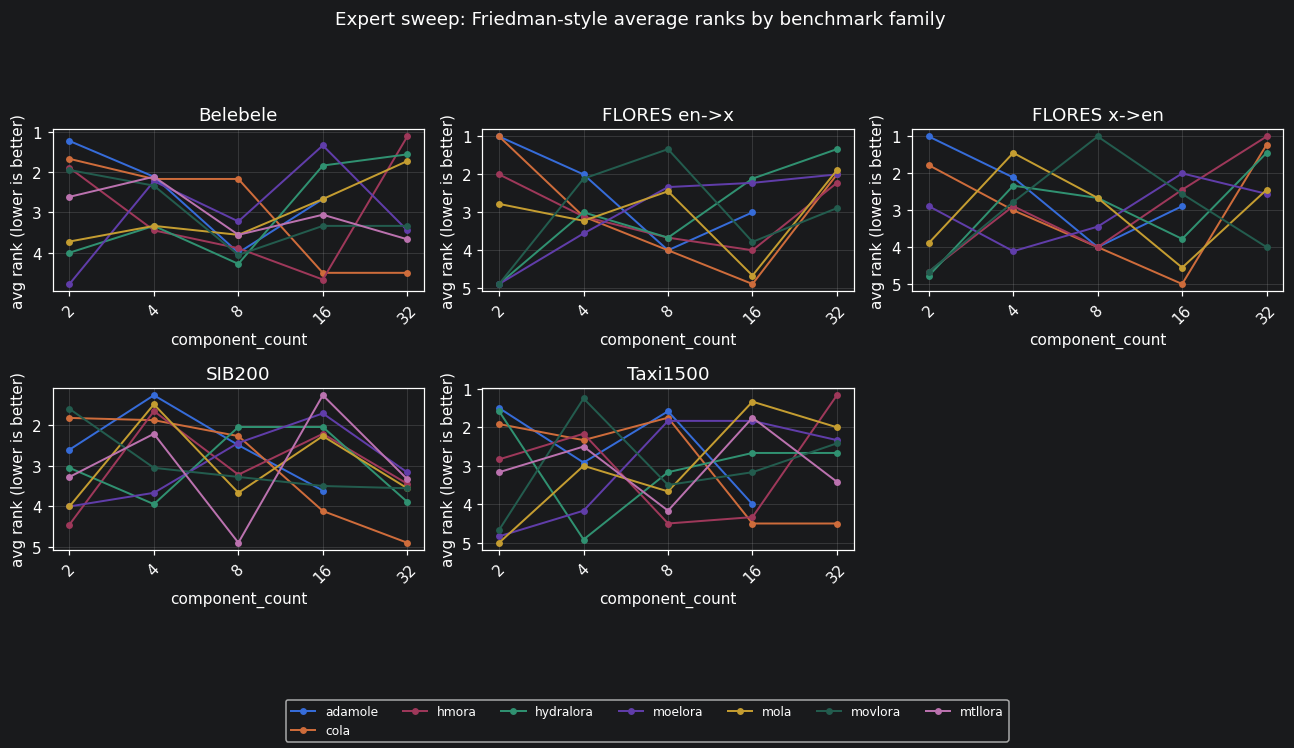

,score_family,kind,component_count,friedman_avg_rank,n_pairs,n_levels
0,Belebele,adamole,2,1.222222,9,4
1,Belebele,adamole,4,2.111111,9,4
3,Belebele,adamole,16,2.666667,9,4
2,Belebele,adamole,8,4.000000,9,4
4,Belebele,cola,2,1.666667,9,5
5,Belebele,cola,4,2.166667,9,5
6,Belebele,cola,8,2.166667,9,5
7,Belebele,cola,16,4.500000,9,5
8,Belebele,cola,32,4.500000,9,5
13,Belebele,hmora,32,1.111111,9,5


In [8]:
expert_exact = exact_value_frame(expert_metrics)
flores_families = ["FLORES en->x", "FLORES x->en"]
drop_cola_flores = {family: ["cola"] for family in flores_families}

plot_benchmark_lines(
  expert_exact,
  "component_count",
  "exact_score",
  "Expert sweep: exact metric values by benchmark family",
  "exact metric value",
  drop_kinds_for_families=drop_cola_flores,
  lower_is_better_flores=True,
)

plot_benchmark_lines(
  expert_exact,
  "component_count",
  "exact_score",
  "Expert sweep: FLORES exact metric values for CoLA only",
  "bits per byte",
  include_kinds=["cola"],
  include_families=flores_families,
  lower_is_better_flores=True,
)

plot_benchmark_lines(
  expert_metrics,
  "component_count",
  "normalized_score",
  "Expert sweep: normalized average scores by benchmark family",
  "normalized score",
  drop_kinds_for_families=drop_cola_flores,
)

expert_rank_trends = friedman_rank_trends(
  expert_metrics,
  "component_count",
  ["task", "language", "metric"],
)
plot_friedman_rank_lines(
  expert_rank_trends,
  "component_count",
  "Expert sweep: Friedman-style average ranks by benchmark family",
  drop_kinds_for_families=drop_cola_flores,
)

display(expert_rank_trends.sort_values(["score_family", "kind", "friedman_avg_rank"]).head(20))


### Configured Rank Trends

For rank sweep plots, the x-axis is configured rank, not total stored capacity rank. This matches the rank significance notebook. For FLORES, the main plots hide CoLA for readability and show CoLA separately.


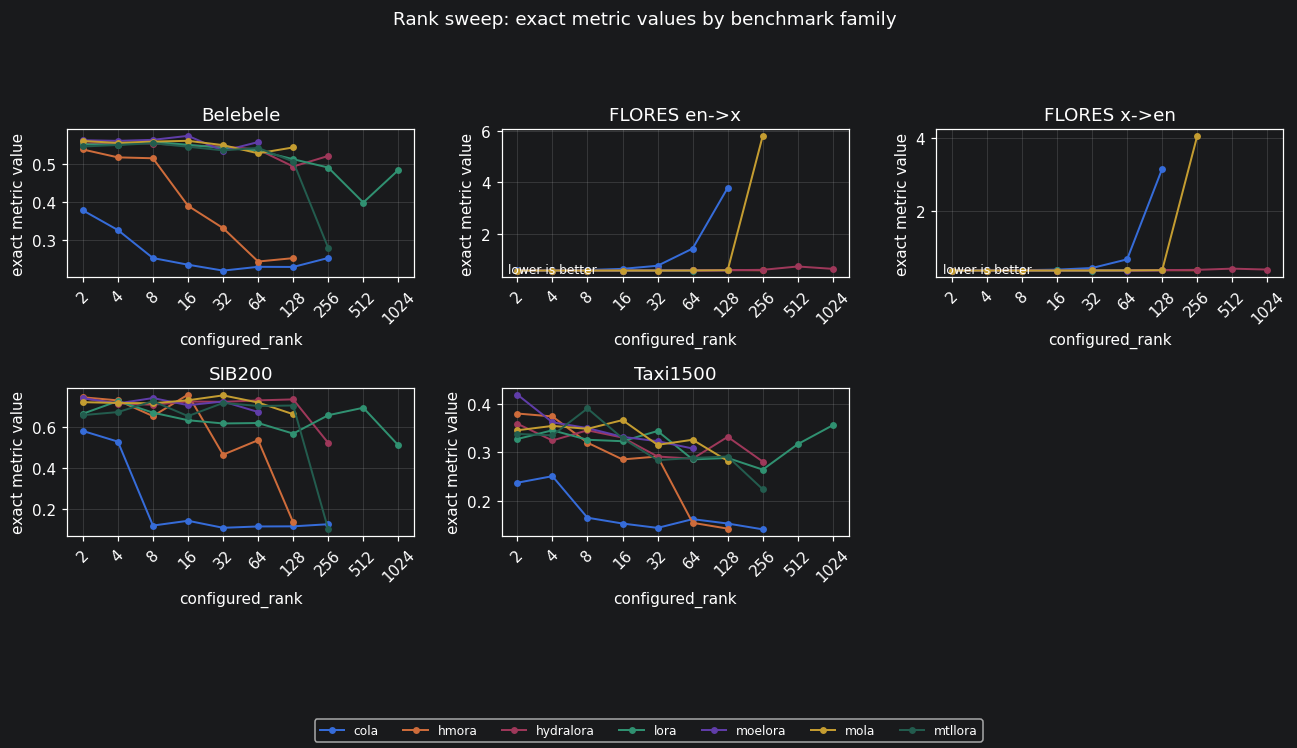

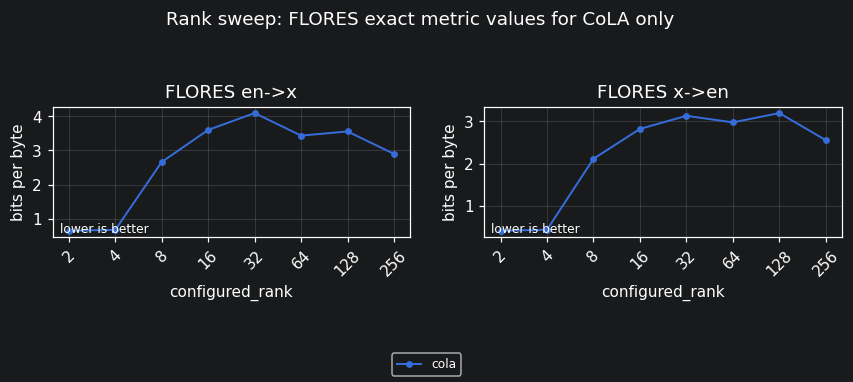

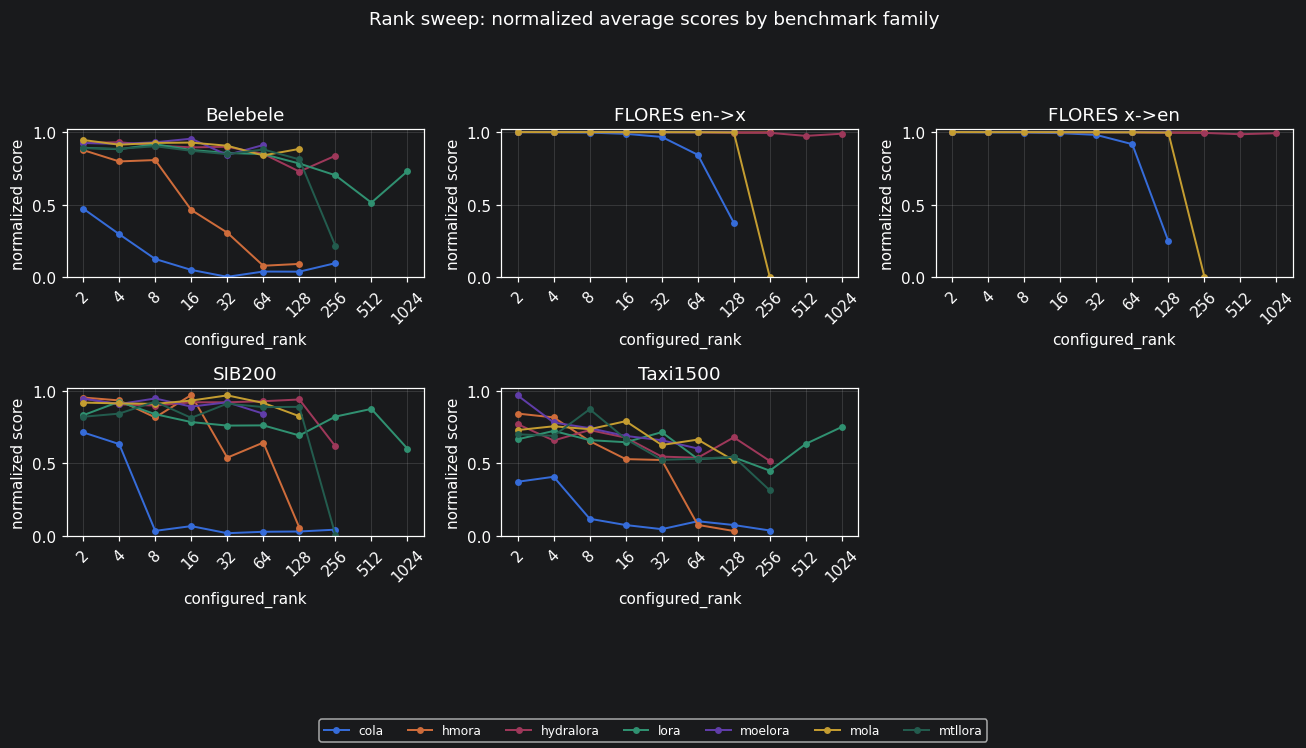

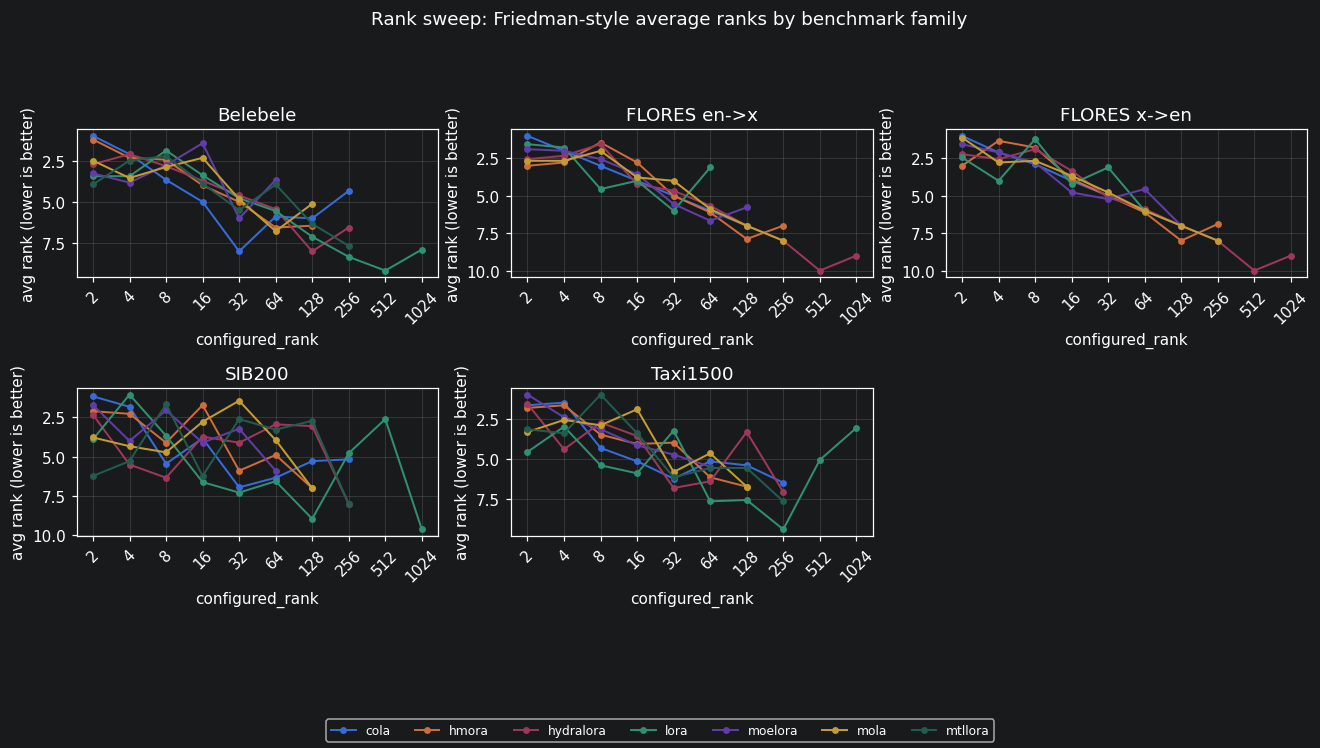

,score_family,kind,configured_rank,friedman_avg_rank,n_pairs,n_levels
0,Belebele,cola,2,1.000000,9,8
1,Belebele,cola,4,2.111111,9,8
2,Belebele,cola,8,3.666667,9,8
7,Belebele,cola,256,4.333333,9,8
3,Belebele,cola,16,5.000000,9,8
5,Belebele,cola,64,5.888889,9,8
6,Belebele,cola,128,6.000000,9,8
4,Belebele,cola,32,8.000000,9,8
8,Belebele,hmora,2,1.222222,9,7
9,Belebele,hmora,4,2.333333,9,7


In [9]:
rank_exact = exact_value_frame(rank_metrics)
drop_cola_flores = {family: ["cola"] for family in flores_families}

plot_benchmark_lines(
  rank_exact,
  "configured_rank",
  "exact_score",
  "Rank sweep: exact metric values by benchmark family",
  "exact metric value",
  drop_kinds_for_families=drop_cola_flores,
  lower_is_better_flores=True,
)

plot_benchmark_lines(
  rank_exact,
  "configured_rank",
  "exact_score",
  "Rank sweep: FLORES exact metric values for CoLA only",
  "bits per byte",
  include_kinds=["cola"],
  include_families=flores_families,
  lower_is_better_flores=True,
)

plot_benchmark_lines(
  rank_metrics,
  "configured_rank",
  "normalized_score",
  "Rank sweep: normalized average scores by benchmark family",
  "normalized score",
  drop_kinds_for_families=drop_cola_flores,
)

rank_rank_trends = friedman_rank_trends(
  rank_metrics,
  "configured_rank",
  ["task", "language", "metric"],
)
plot_friedman_rank_lines(
  rank_rank_trends,
  "configured_rank",
  "Rank sweep: Friedman-style average ranks by benchmark family",
  drop_kinds_for_families=drop_cola_flores,
)

display(rank_rank_trends.sort_values(["score_family", "kind", "friedman_avg_rank"]).head(20))
